# 02 · Relationships: what actually drives 24 h soil moisture change?

Target: **Δ = soil moisture in 24 h − soil moisture now** at 5 cm, in percentage points (pp). Unfrozen soil only.
Each section ends with the feature it motivated (all in `soilcast/features.py`).

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

In [2]:
from soilcast.features import sm_valid, hourly_panel
from soilcast import data
d = pd.read_parquet(PROCESSED / "features_5cm_perfect.parquet")
v = d[sm_valid(d)].copy()
v["dy"] = 100 * (v.sm_t24 - v.sm)
v["sm_pct"] = 100 * v.sm
print(len(v), "issue times (every 3 h) across", v.station.nunique(), "stations")

190210 issue times (every 3 h) across 10 stations


## 1. The target is heavy-tailed: mostly tiny changes, occasional big jumps

{0.01: -3.5, 0.05: -1.9, 0.25: -0.7, 0.5: -0.3, 0.75: 0.0, 0.95: 2.9, 0.99: 10.4}
|dy| < 0.5 pp: 51% of windows
windows with >= 1 mm rain in next 24 h: 20%, share of persistence squared error: 81%


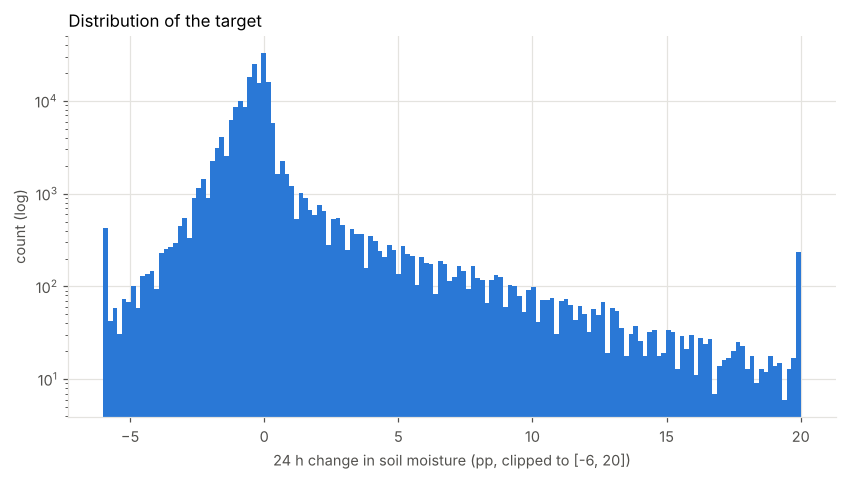

In [3]:
print(v.dy.quantile([.01, .05, .25, .5, .75, .95, .99]).round(2).to_dict())
rain = v.fc_precip_24h >= 1
se = v.dy ** 2   # squared error of persistence (it predicts dy = 0)
print(f"|dy| < 0.5 pp: {(v.dy.abs() < .5).mean():.0%} of windows")
print(f"windows with >= 1 mm rain in next 24 h: {rain.mean():.0%}, share of persistence squared error: {se[rain].sum() / se.sum():.0%}")
fig, ax = plt.subplots()
ax.hist(v.dy.clip(-6, 20), bins=150, color=SERIES[0]); ax.set_yscale("log")
ax.set(xlabel="24 h change in soil moisture (pp, clipped to [-6, 20])", ylabel="count (log)", title="Distribution of the target");

**So:** the problem is mostly "predict the rain response." A loss that downweights big jumps (Huber) is worth trying when tuning (notebook 07).

## 2. Dry-down: wetter soil dries faster (exponential decay)

texture,fine (sand < 20%),medium,sandy (> 50%)
sm_bin,,,
"(0, 5]",NaN,0.30,-0.08
"(5, 10]",-0.05,-0.09,-0.26
"(10, 15]",-0.10,-0.29,-0.63
"(15, 20]",-0.51,-0.50,-0.97
"(20, 25]",-0.70,-0.70,-1.45
"(25, 30]",-0.74,-0.77,-0.50
"(30, 40]",-0.81,-0.77,NaN
"(40, 60]",-1.44,-4.19,NaN


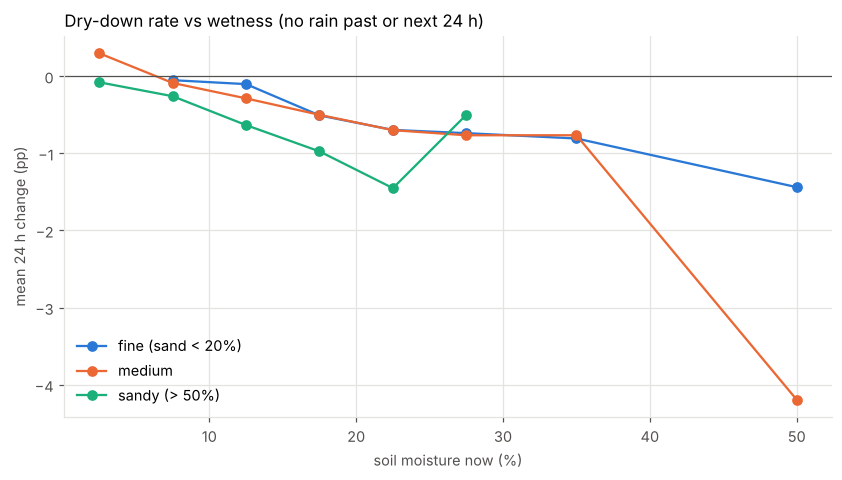

In [4]:
dry = v[(v.fc_precip_24h == 0) & (v.precip_24h == 0)].copy()
dry["texture"] = pd.cut(dry.sand, [0, 20, 50, 100], labels=["fine (sand < 20%)", "medium", "sandy (> 50%)"])
dry["sm_bin"] = pd.cut(dry.sm_pct, [0, 5, 10, 15, 20, 25, 30, 40, 60])
t = dry.groupby(["sm_bin", "texture"], observed=True).dy.mean().unstack()
fig, ax = plt.subplots()
for i, c in enumerate(t.columns):
    ax.plot([iv.mid for iv in t.index], t[c], marker="o", label=c, color=SERIES[i])
ax.axhline(0, color=MUTED, lw=.8)
ax.set(xlabel="soil moisture now (%)", ylabel="mean 24 h change (pp)", title="Dry-down rate vs wetness (no rain past or next 24 h)")
ax.legend(); t.round(2)

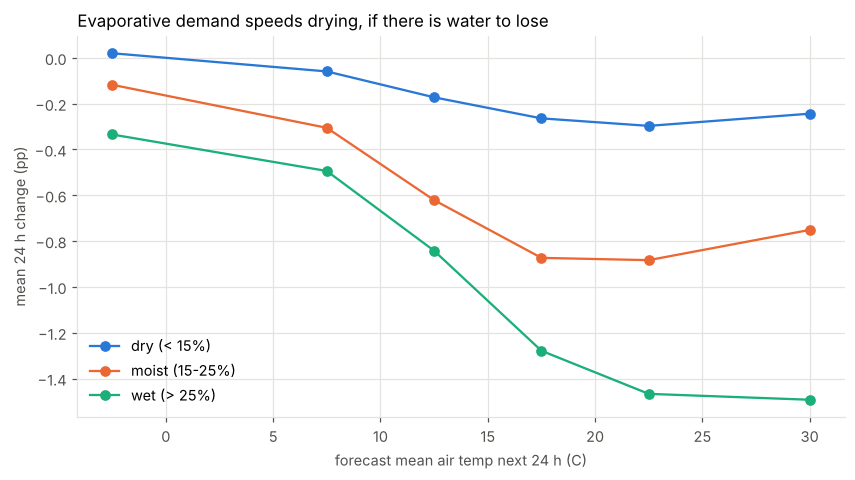

In [5]:
dry["t_bin"] = pd.cut(dry.fc_air_t_mean_24h, [-10, 5, 10, 15, 20, 25, 35])
dry["wet"] = pd.cut(dry.sm_pct, [0, 15, 25, 60], labels=["dry (< 15%)", "moist (15-25%)", "wet (> 25%)"])
t2 = dry.groupby(["t_bin", "wet"], observed=True).dy.mean().unstack()
fig, ax = plt.subplots()
for i, c in enumerate(t2.columns):
    ax.plot([iv.mid for iv in t2.index], t2[c], marker="o", label=c, color=SERIES[i])
ax.set(xlabel="forecast mean air temp next 24 h (C)", ylabel="mean 24 h change (pp)", title="Evaporative demand speeds drying, if there is water to lose")
ax.legend();

### Fitting the dry-down curve on individual events
For every rain event followed by 5 dry days (unfrozen), fit θ(t) − θ_floor = A·e^(−t/τ), with θ_floor fixed at the station's 2nd-percentile growing-season moisture (a stand-in for the driest the soil gets). Fixing the floor makes τ well-determined from 5 days of data; fitting the floor freely as well makes τ unstable (it trades off against the floor).
τ (hours) is the drying time constant: the excess water above the floor shrinks by ~63% every τ hours.

In [6]:
from scipy.stats import spearmanr
u = data.load_uscrn(); soils = data.load_soils()
h = hourly_panel(u, 5)
floor = h[h.st > 5].groupby("station").sm.quantile(0.02)
events = []
for st, g in h.groupby("station"):
    g = g.reset_index(drop=True)
    p24 = g.precip.rolling(24, min_periods=1).sum()
    nxt = g.precip[::-1].rolling(120, min_periods=100).sum()[::-1].shift(-1)
    starts = np.where((p24 >= 5) & (nxt < 0.3) & (g.st > 5))[0]
    last = -10**9
    for i in starts:
        if i - last < 120: continue
        seg = g.iloc[i:i + 120]
        if seg.sm.isna().mean() > .1 or (seg.st <= 1).any(): continue
        k = int(np.nanargmax(seg.sm.to_numpy()[:6])); seg = seg.iloc[k + 6:]   # skip ~6 h of fast drainage
        y = seg.sm.to_numpy() - floor[st]; t = np.arange(len(seg), dtype=float)
        ok = ~np.isnan(y) & (y > 0.002)
        if ok.sum() < 60 or y[ok][0] < 0.01: continue
        slope, icpt = np.polyfit(t[ok], np.log(y[ok]), 1)
        if slope >= 0: continue
        resid = y[ok] - np.exp(icpt + slope * t[ok])
        es = 0.6108 * np.exp(17.27 * seg.air_t / (seg.air_t + 237.3))
        events.append(dict(station=st, start=seg.time_utc.iloc[0], tau_h=-1 / slope, excess_pp=100 * y[ok][0],
                           fit_rmse_pp=100 * np.sqrt(np.mean(resid ** 2)), air_t=seg.air_t.mean(),
                           vpd_kpa=np.nanmean(es * (1 - seg.rh / 100))))
        last = i
ev = pd.DataFrame(events).merge(soils[soils.depth_cm == 5][["station", "sandtotal_r", "claytotal_r"]], on="station")
print(len(ev), "dry-down events; median fit RMSE", ev.fit_rmse_pp.median().round(3), "pp")
ev.groupby("station")[["tau_h", "excess_pp", "fit_rmse_pp", "sandtotal_r", "claytotal_r"]].median().sort_values("tau_h").round(1)

444 dry-down events; median fit RMSE 0.272 pp


,tau_h,excess_pp,fit_rmse_pp,sandtotal_r,claytotal_r
station,,,,,
NE_Whitman_5_ENE,211.1,8.3,0.2,94.0,3.0
NE_Harrison_20_SSE,251.4,16.4,0.5,62.9,12.0
WY_Sundance_8_NNW,265.8,21.4,0.2,30.9,10.0
SD_Pierre_24_S,288.8,23.8,0.4,5.0,53.0
ND_Medora_7_E,317.3,15.2,0.2,36.0,21.0
SD_Aberdeen_35_WNW,347.5,15.2,0.2,38.0,22.0
SD_Sioux_Falls_14_NNE,352.1,18.0,0.2,12.0,26.0
ND_Jamestown_38_WSW,463.0,13.9,0.2,45.0,24.0
MT_Wolf_Point_29_ENE,489.1,25.0,0.5,11.3,21.0


Spearman(tau, VPD) = -0.47 (p = 1e-25);  Spearman(tau, air temp) = -0.49


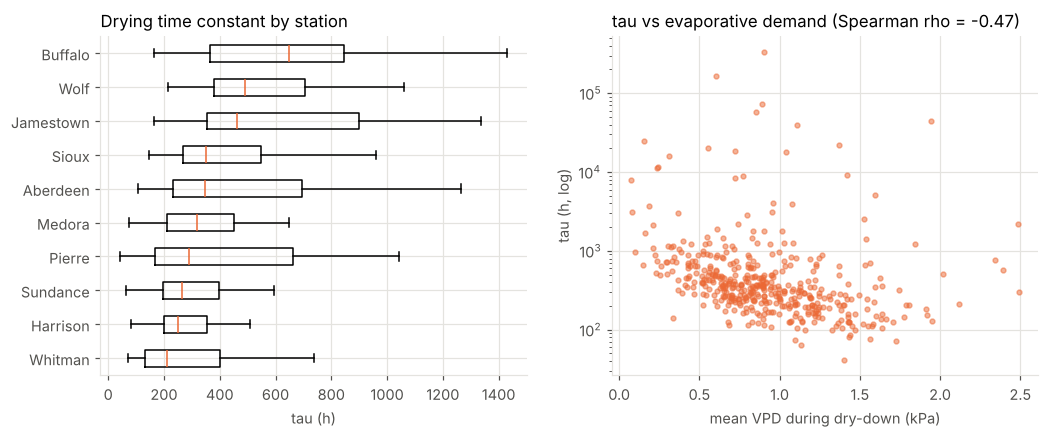

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
order = ev.groupby("station").tau_h.median().sort_values().index
a1.boxplot([ev[ev.station == s].tau_h for s in order], vert=False, showfliers=False)
a1.set_yticks(range(1, len(order) + 1), [s.split("_")[1] for s in order]); a1.set(xlabel="tau (h)", title="Drying time constant by station")
a2.scatter(ev.vpd_kpa, ev.tau_h, s=10, alpha=.5, color=SERIES[1]); a2.set_yscale("log")
rho, pv = spearmanr(ev.vpd_kpa, ev.tau_h, nan_policy="omit")
a2.set(xlabel="mean VPD during dry-down (kPa)", ylabel="tau (h, log)", title=f"tau vs evaporative demand (Spearman rho = {rho:.2f})")
print(f"Spearman(tau, VPD) = {rho:.2f} (p = {pv:.1g});  Spearman(tau, air temp) = {spearmanr(ev.air_t, ev.tau_h, nan_policy='omit')[0]:.2f}")

Read the printed correlation before trusting any story here: a negative rho means higher demand → faster drying (smaller τ). Event-level τ is noisy (roots, crop stage and the floor approximation all vary), which is why the models use the binned relationships above rather than a fitted τ.

**Feature:** `sm_above_floor` (moisture above its 30-day minimum), `drying_demand` = that × forecast ET0 (Hargreaves, from forecast temps), `vpd`.

## 3. Rain response depends on soil texture and on how much room is left

,pp_per_mm,clay,sand,n
station,,,,
NE_Whitman_5_ENE,0.19,3.0,94.0,4058.0
ND_Jamestown_38_WSW,0.24,24.0,45.0,3694.0
SD_Buffalo_13_ESE,0.26,24.0,40.0,3374.0
WY_Sundance_8_NNW,0.33,10.0,30.9,5021.0
SD_Sioux_Falls_14_NNE,0.33,26.0,12.0,3912.0
ND_Medora_7_E,0.34,21.0,36.0,3656.0
SD_Aberdeen_35_WNW,0.36,22.0,38.0,3518.0
NE_Harrison_20_SSE,0.41,12.0,62.9,2896.0
MT_Wolf_Point_29_ENE,0.53,21.0,11.3,2388.0


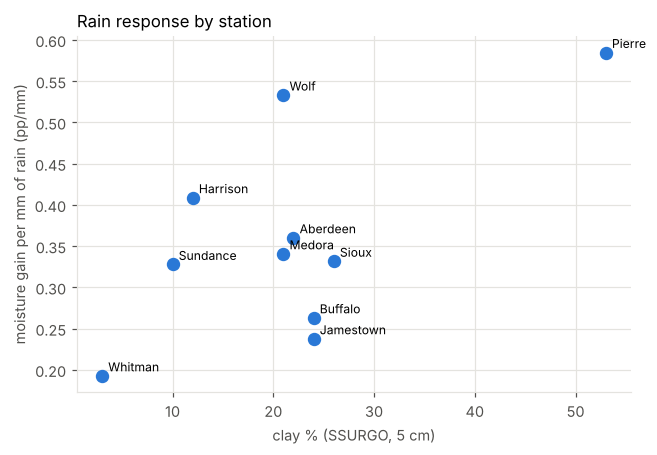

In [8]:
r = v[(v.fc_precip_24h >= 1) & (v.fc_precip_24h <= 30)]
slopes = r.groupby("station").apply(lambda g: pd.Series({"pp_per_mm": np.polyfit(g.fc_precip_24h, g.dy, 1)[0],
                                                         "clay": g.clay.iloc[0], "sand": g.sand.iloc[0], "n": len(g)}))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(slopes.clay, slopes.pp_per_mm, s=60, color=SERIES[0])
for st, s in slopes.iterrows():
    ax.annotate(st.split("_")[1], (s.clay, s.pp_per_mm), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set(xlabel="clay % (SSURGO, 5 cm)", ylabel="moisture gain per mm of rain (pp/mm)", title="Rain response by station")
slopes.sort_values("pp_per_mm").round(2)

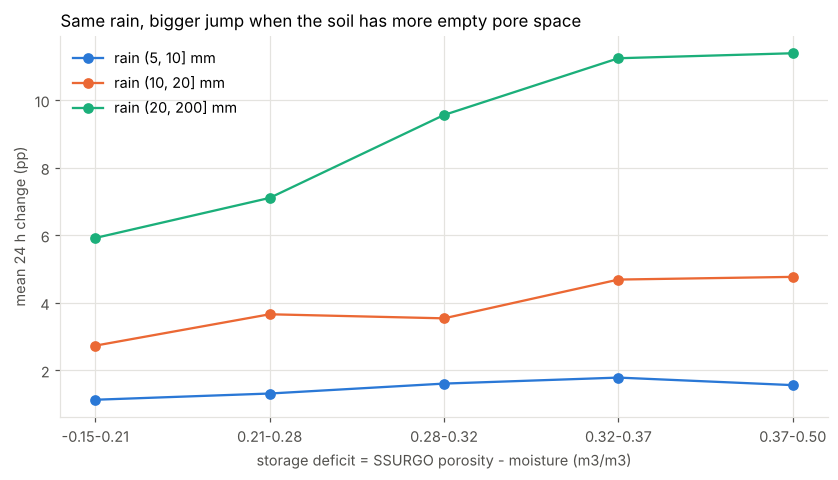

In [9]:
big = v[v.fc_precip_24h >= 5].copy()
big["deficit"] = big.porosity - big.sm
big["deficit_bin"] = pd.qcut(big.deficit, 5)
big["rain_bin"] = pd.cut(big.fc_precip_24h, [5, 10, 20, 200])
t3 = big.groupby(["deficit_bin", "rain_bin"], observed=True).dy.mean().unstack()
fig, ax = plt.subplots()
for i, c in enumerate(t3.columns):
    ax.plot(range(len(t3)), t3[c], marker="o", label=f"rain {c} mm", color=SERIES[i])
ax.set_xticks(range(len(t3)), [f"{iv.left:.2f}-{iv.right:.2f}" for iv in t3.index])
ax.set(xlabel="storage deficit = SSURGO porosity - moisture (m3/m3)", ylabel="mean 24 h change (pp)",
       title="Same rain, bigger jump when the soil has more empty pore space"); ax.legend();

**Feature:** `fc_rain_x_deficit`, `fc_rain_x_clay`, `fc_rain_x_sand`, `fc_rain_x_awc`, `fc_rain_log`. Tree models can find interactions alone, but with only 10 soils they learn them far better when handed explicitly.

## 4. A small daily cycle

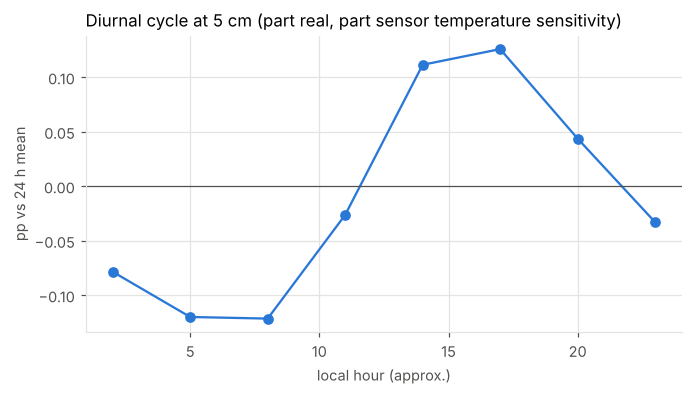

In [10]:
v["local_hour"] = (v.time_utc.dt.hour - 7) % 24   # Mountain Standard Time, approx for the region
dev = (100 * (v.sm - v.sm_24h_mean)).groupby(v.local_hour).mean()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(dev.index, dev.values, marker="o", color=SERIES[0]); ax.axhline(0, color=MUTED, lw=.8)
ax.set(xlabel="local hour (approx.)", ylabel="pp vs 24 h mean", title="Diurnal cycle at 5 cm (part real, part sensor temperature sensitivity)");

**Feature:** hour-of-day encodings (`hod_sin`, `hod_cos`). Only ±0.1 pp, much smaller than rain effects.

## 5. Which inputs move with the target? (rank correlation)

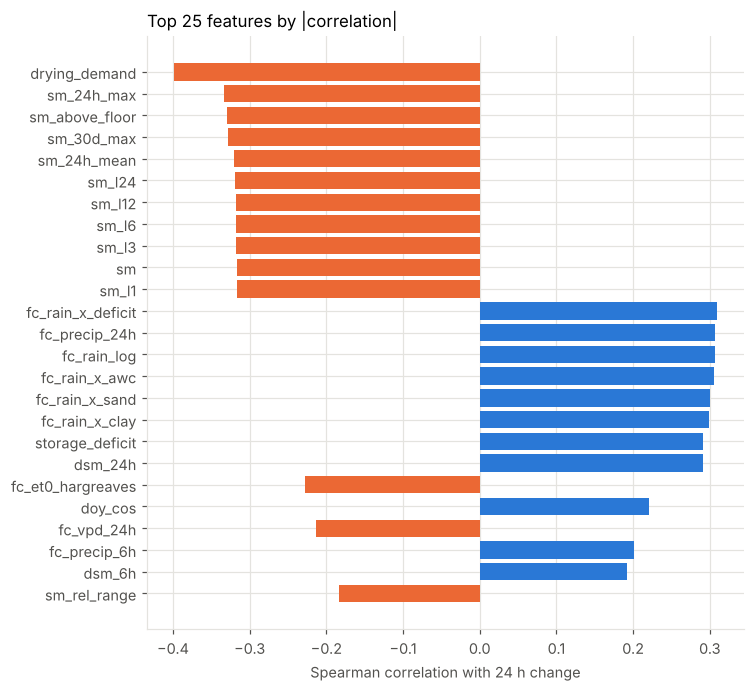

In [11]:
from soilcast.features import FEATURE_SETS
cols = FEATURE_SETS["v2_engineered"]
corr = v[cols + ["dy"]].corr(method="spearman")["dy"].drop("dy").sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(7, 7))
top = corr.head(25)[::-1]
ax.barh(top.index, top.values, color=[SERIES[0] if x > 0 else SERIES[1] for x in top.values])
ax.set(xlabel="Spearman correlation with 24 h change", title="Top 25 features by |correlation|");

Correlation only shows one input at a time; interactions such as rain × deficit matter more inside the models (see SHAP in notebook 03).

## 6. Deeper sensors change less

In [12]:
rows = []
for dep in (5, 10, 20):
    x = pd.read_parquet(PROCESSED / f"features_{dep}cm_perfect.parquet", columns=["sm", "sm_t24", "st", "st_t24", "fc_precip_24h"])
    x = x[sm_valid(x)]; dd = 100 * (x.sm_t24 - x.sm)
    rows.append({"depth_cm": dep, "mean |24h change| pp": dd.abs().mean(), "std pp": dd.std(),
                 "mean change with >=5 mm rain": dd[x.fc_precip_24h >= 5].mean()})
pd.DataFrame(rows).round(2)

,depth_cm,mean |24h change| pp,std pp,mean change with >=5 mm rain
0,5,1.02,2.23,3.84
1,10,0.79,1.82,2.82
2,20,0.46,1.20,1.35


## Summary
| Finding | Feature it motivated |
|---|---|
| Rain windows are ~20% of samples but most of the error | rain forecast features; Huber loss option |
| Dry-down is exponential, faster when wet and warm | `sm_above_floor`, `drying_demand`, `fc_et0_hargreaves`, `vpd` |
| Rain response varies ~3x across stations (lowest in pure sand, highest in heavy clay, but not a clean function of clay alone) and grows with empty pore space | `fc_rain_x_deficit`, `fc_rain_x_clay`, `fc_rain_x_sand`, `fc_rain_x_awc` |
| Small daily cycle | `hod_sin`, `hod_cos` |
| Deeper = smoother | train one model per depth |